# Atividade Prática — Segmentação de Clientes com Aprendizado Não Supervisionado


## Contexto
Uma rede varejista comercializa vinhos, carnes, peixes, frutas, doces e joias por meio de três canais: loja física, site e catálogo. A área de marketing deseja segmentar a base de 2.240 clientes para direcionar campanhas específicas a cada segmento.

## Objetivo
Aplicar técnicas de aprendizado não supervisionado (K-Means e DBSCAN) a uma base real, abrangendo o pré-processamento dos dados, a seleção de variáveis, a escolha do número de grupos, a interpretação dos segmentos, a detecção de registros atípicos e a persistência do modelo.

## Dados
Base *Customer Personality Analysis*, disponível no [Kaggle](https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis/data). Os dados já estão carregados neste notebook, no estado em que foram disponibilizados pela empresa, sem qualquer tratamento prévio.

## Entregável
1. Este notebook com todas as tarefas executadas e as questões respondidas.
2. O arquivo `modelo_segmentos.pkl`, gerado na Parte 5, que será utilizado na aula de implantação (deploy).

## Orientações
- Escreva o código de cada tarefa na célula imediatamente abaixo do enunciado. Crie novas células sempre que necessário.
- Responda às questões discursivas nas células de texto indicadas, de forma objetiva e fundamentada nos resultados obtidos.
- Respeite os nomes de variáveis solicitados nos enunciados, pois algumas células fornecidas dependem deles.
- Não altere o DataFrame original `df`. Todo o tratamento deve ser feito em cópias.
- Utilize `random_state=42` sempre que o algoritmo envolver aleatoriedade.

**Nota de execução:** `df_original` conserva integralmente os dados carregados. Na Tarefa 2.2, `df` é reassociado a uma nova cópia com `Segmento`, para conciliar a preservação dos dados com a coluna exigida nas células fornecidas. As análises mantêm os atípicos até o desafio A, que mede explicitamente sua retirada.


In [1]:
import os, json, hashlib, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, FileLink
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, pairwise_distances
from sklearn.pipeline import make_pipeline
from threadpoolctl import threadpool_limits
import sklearn, joblib
thread_limit = threadpool_limits(limits=1)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False})

In [2]:
arquivo_dados = Path("dados/marketing_campaign.csv")
if not arquivo_dados.exists():
    import kagglehub
    import shutil
    origem = Path(kagglehub.dataset_download("imakash3011/customer-personality-analysis")) / "marketing_campaign.csv"
    arquivo_dados.parent.mkdir(exist_ok=True)
    shutil.copy2(origem, arquivo_dados)
df = pd.read_csv(arquivo_dados, sep="\t")
df_original = df.copy(deep=True)
print(f"{df.shape[0]} clientes e {df.shape[1]} colunas carregados.")
print("Fonte: https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis")
print("SHA256:", hashlib.sha256(arquivo_dados.read_bytes()).hexdigest())

2240 clientes e 29 colunas carregados.
Fonte: https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis
SHA256: cd0affa36b1b981e80ba0e27767e9b3ab723f7a3dba948f722af81abc6b990ea


### Dicionário de dados

**Perfil do cliente**

| Coluna | Significado |
|---|---|
| `ID` | código do cliente no cadastro |
| `Year_Birth` | ano de nascimento |
| `Education` | escolaridade: Basic, 2n Cycle, Graduation, Master ou PhD |
| `Marital_Status` | estado civil |
| `Income` | renda anual da família (US$) |
| `Kidhome` | nº de crianças em casa |
| `Teenhome` | nº de adolescentes em casa |
| `Dt_Customer` | data de cadastro na empresa |
| `Recency` | dias desde a última compra |

**Gastos nos últimos 2 anos (US$)**

| Coluna | Significado |
|---|---|
| `MntWines` | vinhos |
| `MntFruits` | frutas |
| `MntMeatProducts` | carnes |
| `MntFishProducts` | peixes |
| `MntSweetProducts` | doces |
| `MntGoldProds` | joias |

**Compras e canais**

| Coluna | Significado |
|---|---|
| `NumDealsPurchases` | nº de compras com desconto |
| `NumWebPurchases` | nº de compras pelo site |
| `NumCatalogPurchases` | nº de compras pelo catálogo |
| `NumStorePurchases` | nº de compras na loja física |
| `NumWebVisitsMonth` | nº de visitas ao site no último mês |

**Campanhas e atendimento** (1 = sim, 0 = não)

| Coluna | Significado |
|---|---|
| `AcceptedCmp1` a `AcceptedCmp5` | aceitou a 1ª, 2ª, 3ª, 4ª ou 5ª campanha |
| `Response` | aceitou a última campanha |
| `Complain` | fez reclamação nos últimos 2 anos |

**Controle interno da empresa**

| Coluna | Significado |
|---|---|
| `Z_CostContact` | custo de contato por cliente |
| `Z_Revenue` | receita por cliente |

## Parte 1 — Análise exploratória e pré-processamento

**Tarefa 1.1.** Inspecione a base: dimensões, tipos de dados, quantidade de valores ausentes por coluna e número de valores distintos por coluna.

In [3]:
print("Dimensões:", df.shape)
inspecao = pd.DataFrame({"tipo":df.dtypes.astype(str),"ausentes":df.isna().sum(),"distintos":df.nunique(dropna=False)})
display(inspecao)
display(df["Income"].describe(percentiles=[.25,.5,.75,.99]).to_frame())
print("Assimetria de Income:", round(df["Income"].skew(),3))
print("Escolaridade:", df["Education"].value_counts().to_dict())
print("Estado civil:", df["Marital_Status"].value_counts().to_dict())

Dimensões: (2240, 29)


,tipo,ausentes,distintos
ID,int64,0,2240
Year_Birth,int64,0,59
Education,str,0,5
Marital_Status,str,0,8
Income,float64,24,1975
Kidhome,int64,0,3
Teenhome,int64,0,3
Dt_Customer,str,0,663
Recency,int64,0,100
MntWines,int64,0,776


,Income
count,2216.000000
mean,52247.251354
std,25173.076661
min,1730.000000
25%,35303.000000
50%,51381.500000
75%,68522.000000
99%,94458.800000
max,666666.000000


Assimetria de Income: 6.763
Escolaridade: {'Graduation': 1127, 'PhD': 486, 'Master': 370, '2n Cycle': 203, 'Basic': 54}
Estado civil: {'Married': 864, 'Together': 580, 'Single': 480, 'Divorced': 232, 'Widow': 77, 'Alone': 3, 'Absurd': 2, 'YOLO': 2}


**Questão 1.** Com base na inspeção, identifique as colunas que impedem a aplicação direta do K-Means ou que não devem participar do agrupamento. Justifique cada caso.

**Resposta:** `Education` e `Marital_Status` são textos e precisam de codificação. `Dt_Customer` deve virar tempo de relacionamento, não uma cadeia de caracteres. `Income` contém 24 valores ausentes, que impedem o ajuste direto. `ID` identifica pessoas e criaria distâncias sem significado; `Z_CostContact` e `Z_Revenue` são constantes e não discriminam clientes. Campanhas e reclamação são numéricas, mas são resultados de ações/atendimento, não medidas neutras de perfil: serão excluídas na versão B. As escalas de renda, gastos e contagens também exigem padronização; anos de nascimento e renda extremos demandam auditoria, tratada na Parte 4.

**Tarefa 1.2.** Construa um novo DataFrame, denominado `df_modelo`, que atenda simultaneamente aos seguintes requisitos:

1. conter exclusivamente colunas numéricas;
2. não conter valores ausentes;
3. não conter identificadores nem colunas constantes;
4. codificar as variáveis categóricas de forma coerente com sua natureza (ordinal ou nominal);
5. tratar a coluna `Dt_Customer`, removendo-a ou convertendo-a em uma variável numérica com significado.

Ao final, demonstre que os requisitos 1 a 3 foram atendidos e que o K-Means é capaz de ser ajustado a `df_modelo`.

In [4]:
# O objeto recebido não é alterado; a mediana e o esquema são reutilizáveis no deploy.
mediana_renda = float(df_original["Income"].median())
ordem_educacao = {"Basic":0,"2n Cycle":1,"Graduation":2,"Master":3,"PhD":4}
data_referencia = pd.to_datetime(df_original["Dt_Customer"],format="%d-%m-%Y").max() + pd.Timedelta(days=1)
def preparar_clientes(dados, mediana=mediana_renda, referencia=data_referencia):
    base = dados.drop(columns=["Segmento"],errors="ignore").copy(deep=True)
    base["Income"] = base["Income"].fillna(mediana)
    base["Education"] = base["Education"].map(ordem_educacao)
    base["Idade"] = 2014-base.pop("Year_Birth")
    base["Tempo_Cliente_Dias"] = (referencia-pd.to_datetime(base.pop("Dt_Customer"),format="%d-%m-%Y")).dt.days
    civil = base.pop("Marital_Status").replace({"Alone":"Single","Absurd":"Unknown","YOLO":"Unknown"})
    base = base.join(pd.get_dummies(civil,prefix="Marital_Status",dtype=int))
    base = base.drop(columns=["ID","Z_CostContact","Z_Revenue"])
    return base.astype(float)
df_modelo = preparar_clientes(df_original)
assert all(pd.api.types.is_numeric_dtype(t) for t in df_modelo.dtypes)
assert not df_modelo.isna().any().any()
assert not df_modelo.nunique().le(1).any()
assert "ID" not in df_modelo
pd.testing.assert_frame_equal(df, df_original)
teste_kmeans = KMeans(n_clusters=3,random_state=42,n_init=20).fit(df_modelo)
print("Requisitos validados:",df_modelo.shape,"— K-Means ajustado sem erro.")
print("O ajuste sem padronização acima é apenas uma verificação técnica, não o modelo final.")

Requisitos validados: (2240, 31) — K-Means ajustado sem erro.
O ajuste sem padronização acima é apenas uma verificação técnica, não o modelo final.


**Questão 2.** Que estratégia foi adotada para os valores ausentes de `Income`? Justifique a escolha considerando a distribuição dessa variável.

**Resposta:** Os 24 valores ausentes de renda foram preenchidos pela **mediana de US$ 51.381,50**, calculada uma única vez na base de treinamento. A média é US$ 52.247,25 e a assimetria é 6,76, com uma renda extrema de US$ 666.666. A mediana é menos sensível à cauda superior e mantém os 2.240 clientes. É uma aproximação que reduz artificialmente a variabilidade dos casos imputados; para implantação, avalia-se imputação por grupos e monitora-se a taxa de ausência. A mediana utilizada foi persistida para não recalculá-la em novos clientes.

**Questão 3.** Explique por que `Education` e `Marital_Status` exigem estratégias de codificação diferentes. Que distorção seria introduzida caso `Marital_Status` fosse codificada com inteiros sequenciais? Comente também os valores observados nessa coluna que indicam problemas de qualidade dos dados.

**Resposta:** A escolaridade foi tratada como ordinal: Basic < 2n Cycle < Graduation < Master < PhD. A ordenação é uma simplificação documentada (em especial para `2n Cycle`), e os intervalos de uma unidade não representam diferenças exatas de formação. O estado civil é nominal: inteiros sequenciais imporiam uma ordem e distâncias inexistentes entre casado, solteiro, divorciado etc. Por isso foi usado one-hot. `Alone` foi reunido com `Single`; `Absurd` e `YOLO`, categorias sem significado cadastral confiável, foram reunidas em `Unknown`, sem tentar adivinhar o estado civil. A variável permanece na versão A e é retirada integralmente da B.

**Questão 4.** Que tratamento foi dado a `Dt_Customer`? Justifique.

**Resposta:** A data de cadastro foi convertida em `Tempo_Cliente_Dias`, diferença entre o cadastro e uma referência fixa: um dia após o cadastro mais recente da base. A referência é histórica e persistida, em vez da data atual, para que reexecuções não mudem as características. A coluna textual foi removida. Isso representa a duração do relacionamento na fotografia histórica disponível, não o tempo transcorrido até hoje; a data exata é consultável em `data_referencia`.

## Parte 2 — Seleção de variáveis e do número de grupos

**Tarefa 2.1.** Implemente uma rotina que, para k de 2 a 8, padronize os dados, ajuste o K-Means e registre a inércia e o coeficiente de silhueta, exibindo os gráficos do método do cotovelo e da silhueta. Aplique a rotina a dois conjuntos de variáveis:

- **Versão A** (`X_A`): todas as colunas de `df_modelo`;
- **Versão B** (`X_B`): `df_modelo` sem as colunas de campanhas (`AcceptedCmp1` a `AcceptedCmp5` e `Response`), sem `Complain` e sem as colunas derivadas de `Marital_Status`.

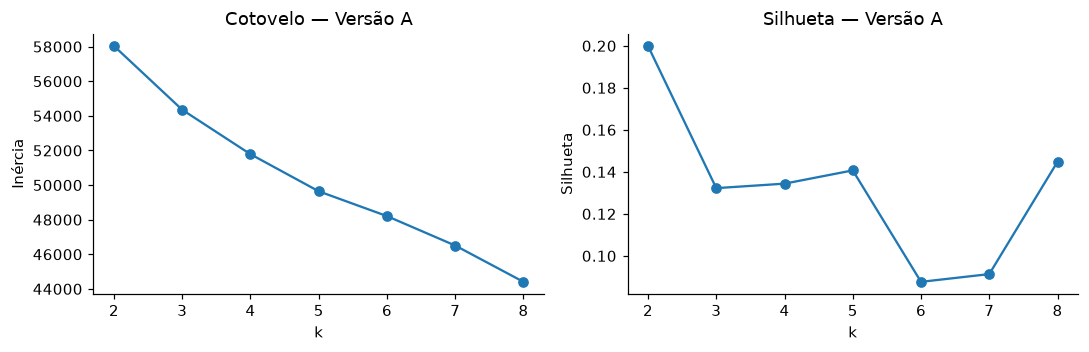

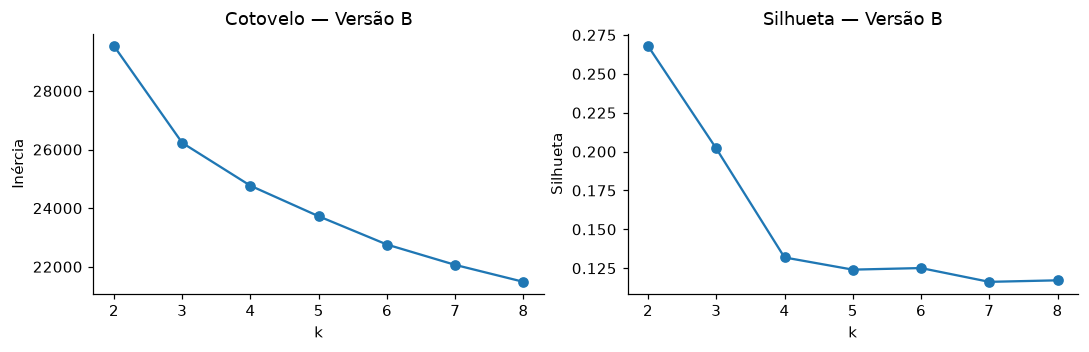

A                                B                     
      inercia silhueta menor_grupo     inercia silhueta menor_grupo
k                                                                  
2  58039.4034   0.1999         884  29534.0177   0.2679         927
3  54353.0782   0.1322         547  26228.5783   0.2020         595
4  51784.9911   0.1344         170  24764.8661   0.1319         531
5  49641.1552   0.1407          21  23722.7133   0.1241         292
6  48207.3006   0.0876          30  22758.1108   0.1251         204
7  46506.1252   0.0913          30  22063.7059   0.1163         182
8  44408.2229   0.1448          21  21485.3951   0.1172         167

In [5]:
campanhas = [f"AcceptedCmp{i}" for i in range(1,6)]+["Response"]
X_A = df_modelo.copy()
excluir = campanhas+["Complain"]+[c for c in df_modelo if c.startswith("Marital_Status_")]
X_B = df_modelo.drop(columns=excluir).copy()
def avaliar_grupos(X, titulo, desenhar=True):
    Z = StandardScaler().fit_transform(X)
    distancias = pairwise_distances(Z)
    np.fill_diagonal(distancias,0)
    linhas=[]
    for k in range(2,9):
        km=KMeans(n_clusters=k,random_state=42,n_init=20).fit(Z)
        linhas.append({"k":k,"inercia":km.inertia_,"silhueta":silhouette_score(distancias,km.labels_,metric="precomputed"),"menor_grupo":int(np.bincount(km.labels_).min())})
    tabela=pd.DataFrame(linhas).set_index("k")
    if desenhar:
        fig,axs=plt.subplots(1,2,figsize=(10,3.3))
        axs[0].plot(tabela.index,tabela.inercia,"o-");axs[0].set(title=f"Cotovelo — {titulo}",xlabel="k",ylabel="Inércia")
        axs[1].plot(tabela.index,tabela.silhueta,"o-");axs[1].set(title=f"Silhueta — {titulo}",xlabel="k",ylabel="Silhueta")
        plt.tight_layout();plt.show()
    return tabela
metricas_A=avaliar_grupos(X_A,"Versão A")
metricas_B=avaliar_grupos(X_B,"Versão B")
display(pd.concat({"A":metricas_A,"B":metricas_B},axis=1).round(4))

**Questão 5.** Compare as duas versões quanto à qualidade do agrupamento. Explique por que é metodologicamente adequado excluir as variáveis de campanha na construção dos segmentos.

**Resposta:** Para k=3, a silhueta passou de **0,1322 (A)** para **0,2020 (B)**. Em ambas, k=2 apresentou maior silhueta (0,1999 e 0,2679), mas não satisfaz o negócio. A versão B separa melhor os clientes e elimina 13 atributos, passando de 31 para 18. Campanhas anteriores dependem de quem recebeu ofertas e de sua reação; incluí-las pode fazer a segmentação reproduzir a estratégia anterior, em vez de revelar perfis de consumo. Elas ficam como variáveis externas para interpretar/validar os segmentos. As métricas são calculadas em espaços diferentes, portanto a comparação de silhueta é indicativa, não prova causal; inércias de A e B não são diretamente comparáveis.

**Tarefa 2.2.** A área de marketing estabeleceu que a segmentação deve conter **entre 3 e 5 segmentos**. Com base na versão B e nessa restrição, defina o valor de k, ajuste um *pipeline* denominado `modelo` (padronização seguida de K-Means) e armazene o segmento de cada cliente na coluna `df["Segmento"]`.

In [6]:
# Três grupos: menor complexidade permitida pelo negócio; as métricas são discutidas na Questão 6.
k_escolhido=3
modelo=make_pipeline(StandardScaler(),KMeans(n_clusters=k_escolhido,random_state=42,n_init=20))
rotulos=modelo.fit_predict(X_B)
# O enunciado pede df["Segmento"], mas proíbe alterar o df original.
# Reassociamos df a uma NOVA cópia com a coluna derivada; df_original conserva os 29 campos brutos.
df=df_original.assign(Segmento=rotulos)
pd.testing.assert_frame_equal(df.drop(columns="Segmento"),df_original)
print("k escolhido:",k_escolhido)
print("Silhueta:",round(silhouette_score(modelo[0].transform(X_B),rotulos),4))
display(df["Segmento"].value_counts().sort_index().rename("clientes").to_frame())

k escolhido: 3
Silhueta: 0.202


,clientes
Segmento,
0,595
1,1038
2,607


**Questão 6.** Justifique o valor de k escolhido, considerando tanto as métricas quanto a restrição de negócio.

**Resposta:** Escolhi **k=3**: dentro de 3 a 5 grupos, a versão B tem silhueta 0,2020 para k=3, 0,1319 para k=4 e 0,1241 para k=5. A inércia cai de 29.534,02 em k=2 para 26.228,58 em k=3 e apresenta ganhos menores nas divisões seguintes. Três é a solução mais simples permitida e apresenta grupos utilizáveis, com 595, 1.038 e 607 clientes; não há um segmento formado por um único atípico. A separação é moderada: esses segmentos são hipóteses operacionais para testes de campanha, não categorias naturais imutáveis.

## Parte 3 — Interpretação dos segmentos

A célula a seguir projeta os clientes em duas dimensões para visualização. Ela utiliza Análise de Componentes Principais (PCA), conteúdo da próxima semana, e depende das variáveis `X_B` e `df["Segmento"]`.

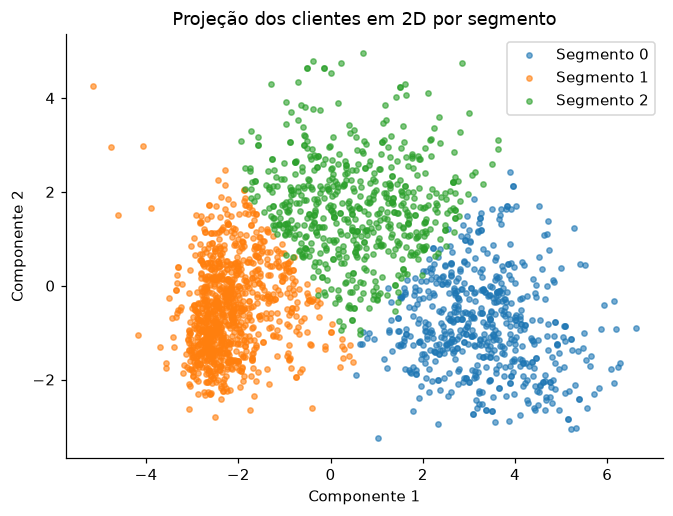

In [7]:
# @title Visualização dos segmentos em 2D (célula fornecida)
from sklearn.decomposition import PCA
pontos_2d = PCA(n_components=2, random_state=42).fit_transform(StandardScaler().fit_transform(X_B))
plt.figure(figsize=(7, 5))
for s in sorted(df["Segmento"].unique()):
    m = (df["Segmento"] == s).to_numpy()
    plt.scatter(pontos_2d[m, 0], pontos_2d[m, 1], s=12, alpha=0.6, label=f"Segmento {s}")
plt.legend(); plt.title("Projeção dos clientes em 2D por segmento")
plt.xlabel("Componente 1"); plt.ylabel("Componente 2")
plt.show()

**Tarefa 3.1.** Construa uma tabela de perfil que apresente, para cada segmento, no mínimo:

- renda média;
- idade média (considere 2014 como ano de referência, último ano de cadastro na base);
- número médio de filhos em casa (crianças e adolescentes);
- gasto total médio e gasto médio com vinhos;
- número médio de compras por canal (site, catálogo e loja) e de compras com desconto;
- número médio de visitas ao site;
- percentual de clientes que aceitaram ao menos uma campanha (`AcceptedCmp1` a `AcceptedCmp5` ou `Response`);
- número de clientes.

In [8]:
gastos=["MntWines","MntFruits","MntMeatProducts","MntFishProducts","MntSweetProducts","MntGoldProds"]
base_perfil=df_original.copy()
base_perfil["Renda"]=base_perfil["Income"].fillna(mediana_renda)
base_perfil["Idade"]=2014-base_perfil["Year_Birth"]
base_perfil["Filhos"]=base_perfil["Kidhome"]+base_perfil["Teenhome"]
base_perfil["Gasto_Total"]=base_perfil[gastos].sum(axis=1)
base_perfil["Aceitou_Campanha"]=base_perfil[campanhas].max(axis=1)*100
colunas_perfil={"renda_media":("Renda","mean"),"idade_media":("Idade","mean"),"filhos_medios":("Filhos","mean"),"gasto_total_medio":("Gasto_Total","mean"),"vinhos_medios":("MntWines","mean"),"compras_site":("NumWebPurchases","mean"),"compras_catalogo":("NumCatalogPurchases","mean"),"compras_loja":("NumStorePurchases","mean"),"compras_desconto":("NumDealsPurchases","mean"),"visitas_site":("NumWebVisitsMonth","mean"),"aceitou_campanha_pct":("Aceitou_Campanha","mean"),"clientes":("ID","size")}
def perfil_de(labels, indices=None):
    base=base_perfil if indices is None else base_perfil.loc[indices]
    return base.assign(Segmento=np.asarray(labels)).groupby("Segmento").agg(**colunas_perfil)
perfil=perfil_de(rotulos)
display(perfil.round(2))

,renda_media,idade_media,filhos_medios,gasto_total_medio,vinhos_medios,compras_site,compras_catalogo,compras_loja,compras_desconto,visitas_site,aceitou_campanha_pct,clientes
Segmento,,,,,,,,,,,,
0,76425.62,45.67,0.22,1351.23,583.70,5.22,5.93,8.42,1.32,2.81,47.39,595
1,35103.83,42.30,1.23,98.05,42.08,2.11,0.55,3.22,2.03,6.44,14.55,1038
2,57828.75,49.67,1.18,743.38,477.49,6.34,3.06,7.61,3.82,5.85,29.00,607


**Tarefa 3.2.** Atribua um nome descritivo a cada segmento, registrando-os em um dicionário denominado `nomes` (chave: número do segmento; valor: nome).

In [9]:
ordem=perfil.sort_values("gasto_total_medio").index.tolist()
nomes={int(ordem[0]):"Econômicos de baixo consumo",int(ordem[1]):"Intermediários multicanal",int(ordem[2]):"Premium de alto consumo"}
display(perfil.assign(nome=pd.Series(nomes)).round(2))

,renda_media,idade_media,filhos_medios,gasto_total_medio,vinhos_medios,compras_site,compras_catalogo,compras_loja,compras_desconto,visitas_site,aceitou_campanha_pct,clientes,nome
Segmento,,,,,,,,,,,,,
0,76425.62,45.67,0.22,1351.23,583.70,5.22,5.93,8.42,1.32,2.81,47.39,595,Premium de alto consumo
1,35103.83,42.30,1.23,98.05,42.08,2.11,0.55,3.22,2.03,6.44,14.55,1038,Econômicos de baixo consumo
2,57828.75,49.67,1.18,743.38,477.49,6.34,3.06,7.61,3.82,5.85,29.00,607,Intermediários multicanal


**Questão 7.** Descreva cada segmento com base na tabela de perfil, justificando o nome atribuído.

**Resposta:**
- **0 — Premium de alto consumo (595 clientes):** renda média US$ 76.425,62, gasto total US$ 1.351,23 e vinhos US$ 583,70; 0,22 filho por residência. Compram em loja (8,42) e catálogo (5,93) e têm a maior aceitação de campanhas (47,39%).
- **1 — Econômicos de baixo consumo (1.038):** renda US$ 35.103,83, gasto US$ 98,05 e vinhos US$ 42,08. Visitam bastante o site (6,44), mas fazem 2,11 compras por esse canal; aceitação de 14,55%. O nome descreve comportamento observado, não capacidade de crédito.
- **2 — Intermediários multicanal (607):** renda US$ 57.828,75, gasto US$ 743,38 e vinhos US$ 477,49. Têm mais compras no site (6,34) e com desconto (3,82), além de 7,61 na loja e 3,06 por catálogo; aceitação de 29,00%.
Os gastos cobrem dois anos e as visitas, o último mês; esses horizontes não devem ser confundidos.

**Questão 8.** O marketing lançará duas campanhas: (a) um clube de assinatura de vinhos importados e (b) cupons de desconto para compras no site. Indique o segmento mais adequado para cada campanha, fundamentando a resposta nos valores da tabela de perfil.

**Resposta:** **(a) Clube de vinhos importados: segmento 0**, pelo maior gasto com vinhos (US$ 583,70), renda média (US$ 76.425,62) e aceitação histórica (47,39%). O segmento 2 também consome vinho e pode ser um público secundário com outra faixa de preço. **(b) Cupons para o site: segmento 2**, que combina mais compras online (6,34), mais compras com desconto (3,82) e 5,85 visitas mensais: maior evidência de uso do canal e afinidade promocional. O segmento 1 é alternativa para um experimento de reativação (6,44 visitas, só 2,11 compras), mas a visita por si só não demonstra conversão nem que o desconto aumentará margem. Recomenda-se teste A/B com grupo de controle e métricas de conversão incremental e margem.

**Questão 9.** Suponha que a empresa pretenda utilizar os segmentos para definir quais clientes podem comprar a prazo, incluindo no modelo as variáveis estado civil e idade. Discuta as implicações éticas e legais dessa proposta.

**Resposta:** Segmentos de marketing **não são um modelo validado de risco de inadimplência**. Usar idade e estado civil para restringir crédito pode produzir discriminação e decisões sem relação demonstrada com a capacidade de pagamento. Essas variáveis não são automaticamente dados sensíveis na definição da LGPD, mas podem atuar como proxies de condições pessoais e gerar efeitos injustos. O tratamento para crédito exige finalidade, base legal e necessidade próprias; não se deve reutilizar indiscriminadamente a finalidade de marketing. Devem existir avaliação de qualidade, minimização, testes de impacto por grupos, explicações compreensíveis e revisão/contestação de decisões automatizadas, nos termos do art. 20. A base de proteção do crédito não elimina os demais princípios e direitos. Seria necessário desenvolver e validar uma solução específica, com supervisão e avaliação jurídica, antes de qualquer uso decisório.

Fonte: [LGPD — arts. 5º, 6º, 7º e 20, texto oficial](https://www.planalto.gov.br/ccivil_03/_ato2015-2018/2018/lei/l13709.htm).

## Parte 4 — Detecção de clientes atípicos

**Tarefa 4.1.** Aplique o DBSCAN à versão B padronizada. Ajuste os parâmetros `eps` e `min_samples` de modo que a proporção de clientes classificados como ruído fique **entre 1% e 5%** da base. Informe os parâmetros adotados e a quantidade de clientes classificados como ruído.

In [10]:
Z_B=modelo[0].transform(X_B)
# Busca transparente: alvo de 3% de ruído dentro do intervalo solicitado.
from sklearn.neighbors import NearestNeighbors
candidatos=[]
for minimo in [10,15,20]:
    dist=NearestNeighbors(n_neighbors=minimo).fit(Z_B).kneighbors()[0][:,-1]
    for eps in np.unique(np.quantile(dist,np.linspace(.70,.99,40))):
        labels=DBSCAN(eps=float(eps),min_samples=minimo).fit_predict(Z_B)
        proporcao=float((labels==-1).mean())
        candidatos.append({"eps":float(eps),"min_samples":minimo,"ruido_pct":100*proporcao,"grupos":len(set(labels)-{-1})})
busca_dbscan=pd.DataFrame(candidatos)
validos=busca_dbscan.query("1 <= ruido_pct <= 5").copy()
assert not validos.empty,"Amplie a grade de parâmetros."
melhor=validos.assign(dist_alvo=lambda t:(t.ruido_pct-3).abs()).sort_values(["dist_alvo","min_samples","eps"]).iloc[0]
eps=float(melhor.eps);min_samples=int(melhor.min_samples)
dbscan=DBSCAN(eps=eps,min_samples=min_samples)
rotulos_dbscan=dbscan.fit_predict(Z_B)
ruido=pd.Series(rotulos_dbscan==-1,index=X_B.index,name="Ruido")
assert .01 <= ruido.mean() <= .05
print(f"eps={eps:.4f}; min_samples={min_samples}; ruído={ruido.sum()} clientes ({100*ruido.mean():.2f}%).")
print("Grupos densos:",len(set(rotulos_dbscan)-{-1}),"— não são os segmentos de marketing do K-Means.")
display(validos.sort_values("ruido_pct").head().round(4))

eps=3.6117; min_samples=15; ruído=67 clientes (2.99%).
Grupos densos: 1 — não são os segmentos de marketing do K-Means.


,eps,min_samples,ruido_pct,grupos
117,4.5280,20,1.0268,1
38,4.5204,10,1.0714,1
116,4.4144,20,1.1161,1
77,4.4265,15,1.1161,1
76,4.3042,15,1.1607,1


**Tarefa 4.2.** Examine os clientes classificados como ruído, ordenando-os por ano de nascimento e por renda, e identifique os registros mais discrepantes.

In [11]:
atipicos=df_original.loc[ruido].copy()
colunas_atipicos=["ID","Year_Birth","Income","Kidhome","Teenhome"]+gastos
print("Ruído: anos de nascimento mais antigos")
display(atipicos.sort_values("Year_Birth")[colunas_atipicos].head(8))
print("Ruído: rendas mais elevadas")
display(atipicos.sort_values("Income",ascending=False)[colunas_atipicos].head(8))
print("Ruído: rendas mais baixas")
display(atipicos.sort_values("Income")[colunas_atipicos].head(5))

Ruído: anos de nascimento mais antigos


,ID,Year_Birth,Income,Kidhome,Teenhome,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds
239,11004,1893,60182.0,0,1,8,0,5,7,0,2
339,1150,1899,83532.0,0,0,755,144,562,104,64,224
192,7829,1900,36640.0,1,0,15,6,8,7,4,25
803,9930,1944,82716.0,0,0,606,148,228,15,148,22
1898,4619,1945,113734.0,0,0,6,2,3,1,262,3
1444,1553,1946,82657.0,0,0,966,168,672,246,105,126
644,1173,1947,77632.0,0,0,1200,105,758,0,42,147
2132,11181,1949,156924.0,0,0,2,1,2,1,1,1


Ruído: rendas mais elevadas


,ID,Year_Birth,Income,Kidhome,Teenhome,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds
2233,9432,1977,666666.0,1,0,9,14,18,8,1,12
617,1503,1976,162397.0,1,1,85,1,16,2,1,2
687,1501,1982,160803.0,0,0,55,16,1622,17,3,4
1300,5336,1971,157733.0,1,0,39,1,9,2,0,8
164,8475,1973,157243.0,0,1,20,2,1582,1,2,1
1653,4931,1977,157146.0,0,0,1,0,1725,2,1,1
2132,11181,1949,156924.0,0,0,2,1,2,1,1,1
655,5555,1975,153924.0,0,0,1,1,1,1,1,1


Ruído: rendas mais baixas


,ID,Year_Birth,Income,Kidhome,Teenhome,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds
1245,6862,1971,1730.0,0,0,1,1,3,1,1,1
21,5376,1979,2447.0,1,0,1,1,1725,1,1,1
1846,9931,1963,4023.0,1,1,5,0,1,1,1,1
1975,10311,1969,4428.0,0,1,16,4,12,2,4,321
9,5899,1950,5648.0,1,1,28,0,6,1,1,13


**Questão 10.** Classifique os registros mais discrepantes como prováveis erros de dados ou como clientes legítimos fora do padrão. Proponha um tratamento para cada caso.

**Resposta:** Os IDs **11004, 1150 e 7829**, nascidos em 1893, 1899 e 1900, teriam 121, 115 e 114 anos em 2014: são prováveis erros cadastrais, a verificar na fonte. Não se deve inventar o ano correto; após auditoria, corrige-se com evidência, trata-se como ausente ou exclui-se apenas da modelagem, preservando o registro bruto. O ID **9432**, com renda **US$ 666.666**, é fortemente suspeito, mas a renda isolada não prova erro: deve ser confirmada antes de corrigir, imputar ou limitar sua influência. Já rendas de US$ 162.397 (ID 1503), US$ 160.803 (1501) e US$ 157.733 (5336) podem pertencer a clientes legítimos de renda alta; devem ser mantidas se verificadas, considerando transformações robustas em uma nova comparação. Ruído no DBSCAN significa baixa densidade multivariada, não fraude nem erro automático. Os parâmetros encontrados são eps=3,6117 e min_samples=15: 67 registros, **2,99%** da base. A remoção no desafio A é um experimento, não uma regra universal de exclusão.

## Parte 5 — Persistência do modelo

**Tarefa 5.1.** Salve, no arquivo `modelo_segmentos.pkl`, um único objeto que contenha: o *pipeline* treinado (`modelo`), a lista ordenada das colunas utilizadas no treinamento e o dicionário `nomes`.

**Tarefa 5.2.** Demonstre o uso do arquivo: carregue-o em uma nova variável e classifique pelo menos um cliente da base, exibindo o número e o nome do segmento atribuído.

**Tarefa 5.3.** Faça o download do arquivo. Ele será utilizado na aula de implantação.

In [12]:
artefato={"modelo":modelo,"colunas":X_B.columns.tolist(),"nomes":nomes,
          "preprocessamento":{"mediana_renda":mediana_renda,"data_referencia":data_referencia.isoformat(),"ano_idade":2014,"ordem_educacao":ordem_educacao},
          "versoes":{"python":platform.python_version(),"sklearn":sklearn.__version__,"pandas":pd.__version__}}
joblib.dump(artefato,"modelo_segmentos.pkl")
carregado=joblib.load("modelo_segmentos.pkl")
cliente=preparar_clientes(df_original.iloc[[0]],mediana=carregado["preprocessamento"]["mediana_renda"],referencia=pd.Timestamp(carregado["preprocessamento"]["data_referencia"]))
cliente=cliente.reindex(columns=carregado["colunas"])
segmento=int(carregado["modelo"].predict(cliente)[0])
assert segmento==int(rotulos[0])
print(f"Cliente ID {int(df_original.iloc[0]['ID'])}: segmento {segmento} — {carregado['nomes'][segmento]}")
assert np.array_equal(carregado["modelo"].predict(X_B[carregado["colunas"]]),rotulos)
# Download no Colab e link clicável em Jupyter; o arquivo também fica junto deste notebook.
try:
    from google.colab import files
except ImportError:
    display(FileLink("modelo_segmentos.pkl"))
else:
    files.download("modelo_segmentos.pkl")

Cliente ID 5524: segmento 0 — Premium de alto consumo


C:\Users\renzo\Documents\clustering-pratica\modelo_segmentos.pkl

## Desafio Final

**A.** Remova de `X_B` os clientes identificados como ruído na Parte 4 e repita a Tarefa 2.1. Analise o efeito sobre a silhueta e sobre os perfis dos segmentos.

**B.** Construa um conjunto reduzido com no máximo seis variáveis derivadas da base (por exemplo, renda, idade, total de filhos, gasto total, total de compras e visitas ao site). Compare a qualidade do agrupamento com a da versão B e discuta as vantagens de um conjunto reduzido para a implantação do modelo.

**C.** Ajuste o modelo com k = 4 e reconstrua a tabela de perfil. Identifique qual segmento foi subdividido e avalie se a nova divisão é útil para o marketing.

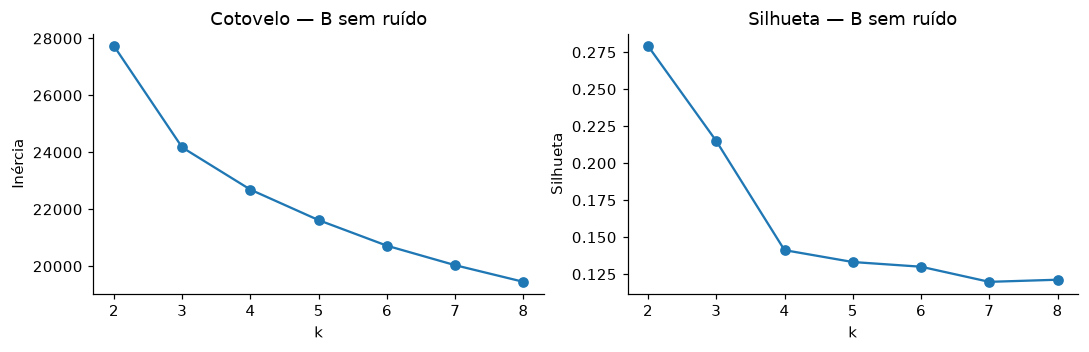

B completa                      B sem ruído                     
      inercia silhueta menor_grupo     inercia silhueta menor_grupo
k                                                                  
2  29534.0177   0.2679         927  27735.2091   0.2792         881
3  26228.5783   0.2020         595  24171.9169   0.2150         561
4  24764.8661   0.1319         531  22689.8367   0.1412         521
5  23722.7133   0.1241         292  21617.9280   0.1332         228
6  22758.1108   0.1251         204  20720.7523   0.1300         203
7  22063.7059   0.1163         182  20036.3759   0.1198         190
8  21485.3951   0.1172         167  19452.2427   0.1212         169

,renda_media,idade_media,filhos_medios,gasto_total_medio,vinhos_medios,compras_site,compras_catalogo,compras_loja,compras_desconto,visitas_site,aceitou_campanha_pct,clientes
Segmento,,,,,,,,,,,,
0,75149.39,46.04,0.21,1343.29,591.67,5.14,5.80,8.52,1.23,2.74,47.24,561
1,34409.66,42.03,1.23,94.16,39.39,2.09,0.54,3.21,1.96,6.41,14.34,1004
2,57302.24,49.72,1.20,709.91,457.46,6.22,2.97,7.54,3.83,5.88,28.29,608


Os rótulos são arbitrários: compare os perfis por gasto, não apenas pelo número.


In [13]:
X_sem_ruido=X_B.loc[~ruido].copy()
metricas_sem_ruido=avaliar_grupos(X_sem_ruido,"B sem ruído")
modelo_sem_ruido=make_pipeline(StandardScaler(),KMeans(n_clusters=k_escolhido,random_state=42,n_init=20))
labels_sem=modelo_sem_ruido.fit_predict(X_sem_ruido)
perfil_sem_ruido=perfil_de(labels_sem,X_sem_ruido.index)
display(pd.concat({"B completa":metricas_B,"B sem ruído":metricas_sem_ruido},axis=1).round(4))
display(perfil_sem_ruido.round(2))
print("Os rótulos são arbitrários: compare os perfis por gasto, não apenas pelo número.")

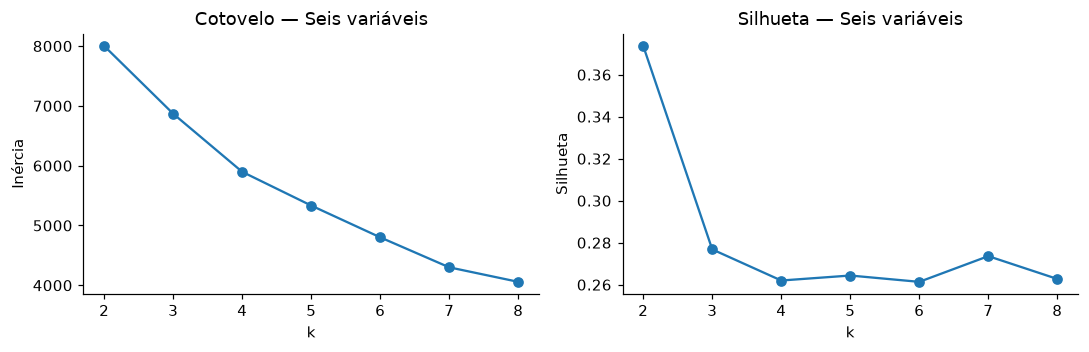

B                        Reduzido                     
      inercia silhueta menor_grupo    inercia silhueta menor_grupo
k                                                                 
2  29534.0177   0.2679         927  8001.7800   0.3737         964
3  26228.5783   0.2020         595  6868.6980   0.2768         667
4  24764.8661   0.1319         531  5897.3474   0.2620         485
5  23722.7133   0.1241         292  5333.5082   0.2644           1
6  22758.1108   0.1251         204  4801.9489   0.2614           1
7  22063.7059   0.1163         182  4300.5210   0.2736           1
8  21485.3951   0.1172         167  4057.8700   0.2627           1

In [14]:
X_reduzido=pd.DataFrame({"Renda":base_perfil.Renda,"Idade":base_perfil.Idade,"Filhos":base_perfil.Filhos,
    "Gasto_Total":base_perfil.Gasto_Total,"Compras_Total":df_original[["NumWebPurchases","NumCatalogPurchases","NumStorePurchases"]].sum(axis=1),
    "Visitas_Site":df_original.NumWebVisitsMonth})
assert X_reduzido.shape[1]<=6
metricas_reduzido=avaliar_grupos(X_reduzido,"Seis variáveis")
display(pd.concat({"B":metricas_B,"Reduzido":metricas_reduzido},axis=1).round(4))

In [15]:
modelo_k4=make_pipeline(StandardScaler(),KMeans(n_clusters=4,random_state=42,n_init=20))
rotulos_k4=modelo_k4.fit_predict(X_B)
perfil_k4=perfil_de(rotulos_k4)
cruzamento=pd.crosstab(pd.Series(rotulos,name="k=3"),pd.Series(rotulos_k4,name="k=4"))
display(perfil_k4.round(2));display(cruzamento)
print("Silhueta k=3:",round(metricas_B.loc[3,"silhueta"],4),"| k=4:",round(metricas_B.loc[4,"silhueta"],4))
# Auditoria final: nenhuma coluna bruta foi modificada.
pd.testing.assert_frame_equal(df.drop(columns="Segmento"),df_original)
resumo={"metricas_A":metricas_A.reset_index().to_dict("records"),"metricas_B":metricas_B.reset_index().to_dict("records"),
"perfil":perfil.reset_index().to_dict("records"),"nomes":nomes,"eps":eps,"min_samples":min_samples,"ruido_n":int(ruido.sum()),
"atipicos":atipicos.sort_values("Year_Birth")[["ID","Year_Birth","Income"]].head(5).to_dict("records"),
"rendas_altas":atipicos.nlargest(5,"Income")[["ID","Year_Birth","Income"]].to_dict("records"),
"sem_ruido":metricas_sem_ruido.reset_index().to_dict("records"),"reduzido":metricas_reduzido.reset_index().to_dict("records"),
"perfil_sem_ruido":perfil_sem_ruido.reset_index().to_dict("records"),"perfil_k4":perfil_k4.reset_index().to_dict("records"),"cruzamento":cruzamento.to_dict(),
"mediana_renda":mediana_renda,"media_renda":float(df_original.Income.mean()),"assimetria_renda":float(df_original.Income.skew()),
"colunas_A":len(X_A.columns),"colunas_B":len(X_B.columns)}
Path("resultados.json").write_text(json.dumps(resumo,ensure_ascii=False,indent=2),encoding="utf-8")
print("Validação final: dados brutos preservados; modelo recarregado produz os mesmos segmentos.")

,renda_media,idade_media,filhos_medios,gasto_total_medio,vinhos_medios,compras_site,compras_catalogo,compras_loja,compras_desconto,visitas_site,aceitou_campanha_pct,clientes
Segmento,,,,,,,,,,,,
0,29655.26,35.92,0.88,100.01,33.23,2.24,0.51,3.13,1.92,6.96,16.75,585
1,58843.37,49.23,1.12,812.17,522.45,6.59,3.30,7.99,3.78,5.82,30.54,537
2,43599.39,50.89,1.67,129.07,73.95,2.35,0.76,3.63,2.42,5.79,12.81,531
3,76515.45,45.60,0.21,1352.32,581.86,5.20,5.94,8.39,1.31,2.79,47.53,587


k=4,0,1,2,3
k=3,,,,
0,0,9,0,586
1,580,0,457,1
2,5,528,74,0


Silhueta k=3: 0.202 | k=4: 0.1319
Validação final: dados brutos preservados; modelo recarregado produz os mesmos segmentos.


## Análise do desafio final

**A — Sem ruído.** A exclusão de 67 registros deixou 2.173 clientes. Em k=3, a silhueta melhorou de **0,2020 para 0,2150**; em k=2, de 0,2679 para 0,2792. Os perfis centrais permaneceram: gastos médios, ordenados do menor ao maior, passaram de US$ 98,05 / 743,38 / 1.351,23 para US$ 94,16 / 709,91 / 1.343,29. Os grupos passaram a 1.004 / 608 / 561 clientes; não são apenas os grupos anteriores menos seus atípicos, pois o scaler e os centroides foram ajustados novamente. A melhora é pequena e usa uma população selecionada; não justifica excluir automaticamente clientes legítimos raros.

**B — Seis variáveis.** Em k=3, a silhueta foi **0,2768**, acima dos 0,2020 da B; em k=2, 0,3737 contra 0,2679. Há menos redundância, menos dados a coletar e menor manutenção no deploy. Em contrapartida, totalizar gastos e compras perde preferências por produtos e canais. As silhuetas usam geometrias diferentes e não garantem maior eficácia comercial. A partir de k=5 surgiu um grupo de um único registro na versão reduzida: a renda extrema continua sendo um ponto de atenção. O modelo reduzido foi comparado, mas o artefato principal continua sendo o pipeline solicitado para X_B.

**C — Quatro grupos.** O segmento econômico (k=3, grupo 1) foi principalmente repartido: **580 clientes foram para k=4/grupo 0 e 457 para grupo 2**. Não se trata de uma hierarquia exata: outros clientes também mudaram de grupo. Os novos grupos econômicos têm idade média **35,92 vs. 50,89**, filhos **0,88 vs. 1,67**, renda **US$ 29.655,26 vs. 43.599,39** e visitas ao site **6,96 vs. 5,79**. Isso sugere hipóteses de comunicação para fases de vida diferentes, sem usar os rótulos para restringir direitos. Entretanto, a silhueta cai de **0,2020 para 0,1319** e o comportamento de gasto continua próximo (US$ 100,01 vs. 129,07). Manteria k=3 para implantação inicial; k=4 só se um teste de campanha demonstrar ganho incremental suficiente para a complexidade adicional.

### Reprodutibilidade e implantação
Execute todas as células, na ordem, a partir desta pasta; instale as versões de `requirements.txt` em um ambiente Python compatível. O CSV é uma cópia da base pública indicada no enunciado, e seu SHA256 aparece na carga. O `modelo_segmentos.pkl` contém pipeline, colunas ordenadas, nomes, parâmetros de preparação e versões. Para novos clientes, aplique `preparar_clientes` com a mediana e a referência persistidas e reordene pelas colunas do artefato, como demonstrado na Parte 5. Carregue somente arquivos pickle/joblib de origem confiável. Não se deve ajustar o scaler novamente na implantação. As conclusões são descritivas desta base; valide estabilidade e resultados de campanhas antes de uso operacional.
